# 05 — The −95 minute q99 precursor motif

## Why this module exists

After extending q99 event anatomy to ±120 minutes, a visually coherent pattern appeared around roughly **95 minutes before q99 onset** in several feature families.

This module does not assume that one exact candle is magical. It freezes a five-candle local window:

\[
-105,-100,-95,-90,-85\text{ minutes}
\]

and asks whether the shape is repeatable.

Because this motif was discovered by looking at the same sample, all results here are **exploratory characterization**, not confirmatory inference or out-of-sample prediction.

## Main protection: prior-q99 contamination

A q99 event can occur less than two hours after another q99 event. Such cases could make an apparent −95m pattern nothing more than the aftermath of the earlier shock.

The primary Module 05 sample therefore requires:

\[
\text{no prior q99 bar in }[t_0-120m,t_0).
\]

The all-event sample is retained only as a comparison.


In [1]:
from pathlib import Path
import json, os, sys, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 180)
pd.set_option('display.width', 300)
pd.set_option('display.max_rows', 300)

load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
DB_PATH = DATA_ROOT / 'database' / 'research.duckdb'
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
SRC = PROJECT_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from data_engineering.modeling import volatility_q99_precursors as qp
from data_engineering.modeling import volatility_q99_conditional as qc
from data_engineering.modeling import volatility_q99_motif95 as qm

START = os.getenv('VD5_START', '').strip() or None
END = os.getenv('VD5_END', '').strip() or None
ASSET_FILTER = [x.strip().upper() for x in os.getenv('VD5_ASSETS', '').split(',') if x.strip()]
MAX_CONTROLS = int(os.getenv('VD5_MAX_CONTROLS', str(qc.DEFAULT_MAX_CONTROLS)))
MIN_CONTROLS = int(os.getenv('VD5_MIN_CONTROLS', str(qc.DEFAULT_MIN_CONTROLS)))
MIN_ENV_DIMS = int(os.getenv('VD5_MIN_ENV_DIMS', str(qc.DEFAULT_MIN_ENV_DIMS)))
OUT = PROJECT_ROOT / 'notebooks' / 'Volatility_Dynamics' / '05'
OUT.mkdir(parents=True, exist_ok=True)

print('Module 03 engine:', qp.VERSION)
print('Module 04 engine:', qc.VERSION)
print('Module 05 engine:', qm.VERSION)
print('Module 05 selftest:', qm.selftest())


Module 03 engine: 0.2.0
Module 04 engine: 0.1.0
Module 05 engine: 0.1.0
Module 05 selftest: {'five_bar_motif_window': True, 'center_is_minus_95m': True, 'simultaneous_timestamp_collapse': True, 'l2_rebound_metric': True}


## 1. Frozen motif feature contract

The motif study does not reopen the 205-feature search. It carries forward the Module 03/04 candidate families that motivated the visual observation:

- native range / trading activity;
- option IV levels;
- spread / book activity;
- L2 zero-cross / transition / roughness instability.


In [2]:
con = duckdb.connect(str(DB_PATH), read_only=True)
schema = con.execute('DESCRIBE time_series_feature_state').df()
available = set(schema['column_name'].astype(str))
contract = qm.motif_contract(available)
display(contract)
features = contract.loc[contract.present, 'feature'].tolist()
missing_features = contract.loc[~contract.present, 'feature'].tolist()
if missing_features:
    print('missing motif features:', missing_features)


,feature,family,reason,present
0,intrabar_range_bps,activity,Module 03/04 broad activity or native-range pr...,True
1,volume_usd,activity,Module 03/04 broad activity or native-range pr...,True
2,trade_count,activity,Module 03/04 broad activity or native-range pr...,True
3,option_iv_atm_forward,iv_level,Module 03/04 elevated option-IV level,True
4,iv_put_25d,iv_level,Module 03/04 elevated option-IV level,True
5,iv_call_25d,iv_level,Module 03/04 elevated option-IV level,True
6,book_twa_spread_bps,liquidity_book_activity,Module 03/04 spread or book-activity precursor,True
7,book_update_count,liquidity_book_activity,Module 03/04 spread or book-activity precursor,True
8,book_obi_20_raw_zero_cross_count,l2_instability,Module 03/04 sparse L2 instability precursor,True
9,book_obi_20_transition_count,l2_instability,Module 03/04 sparse L2 instability precursor,True


## 2. Load raw q99 source plus frozen motif fields


In [3]:
def qident(name):
    return '"' + str(name).replace('"', '""') + '"'

select_cols = list(dict.fromkeys(['state_time','underlying','return_5m'] + features))
where = []
if START:
    ts = pd.Timestamp(START)
    ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
    where.append(f"state_time >= TIMESTAMPTZ '{ts.isoformat()}'")
if END:
    ts = pd.Timestamp(END)
    ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
    end_ts = ts + pd.Timedelta(days=1)
    where.append(f"state_time < TIMESTAMPTZ '{end_ts.isoformat()}'")
if ASSET_FILTER:
    where.append('underlying IN (' + ','.join(repr(x) for x in ASSET_FILTER) + ')')
where_sql = '' if not where else ' WHERE ' + ' AND '.join(where)
sql = (
    'SELECT ' + ', '.join(qident(c) for c in select_cols)
    + ' FROM time_series_feature_state' + where_sql
    + ' ORDER BY underlying, state_time'
)
df = con.execute(sql).df()
con.close()
df['state_time'] = pd.to_datetime(df['state_time'], utc=True)
df = df.reset_index(drop=True)
if df.empty:
    raise RuntimeError('No rows found.')
dupes = int(df.duplicated(['underlying','state_time']).sum())
if dupes:
    raise RuntimeError(f'Found {dupes} duplicate asset/timestamp rows.')
print(f'rows {len(df):,} | assets {sorted(df.underlying.unique())}')
print(df.state_time.min(), '->', df.state_time.max())


rows 38,304 | assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP']
2026-09-19 08:00:00+00:00 -> 2026-10-08 07:55:00+00:00


## 3. Recompute q99 and audit prior-q99 contamination


In [4]:
events, event_meta = qp.identify_q99_onsets(df)
origins = qp.build_origin_index(df, events)
clean_events, clean_origins, contamination = qm.clean_event_and_origin_sets(
    df, events, origins, lookback_min=qm.PRIOR_Q99_LOOKBACK_MIN
)
if clean_events.empty:
    raise RuntimeError('No clean q99 events remain after prior-q99 exclusion.')

summary = pd.DataFrame({
    'sample': ['all_q99_onsets','clean_no_prior_q99_120m'],
    'n_asset_events': [len(events), len(clean_events)],
    'n_unique_event_times': [events.event_time.nunique(), clean_events.event_time.nunique()],
})
display(summary)
display(contamination.prior_q99_bar_lookback.value_counts(dropna=False).rename_axis('prior_q99').to_frame('n_events'))
display(contamination[contamination.prior_q99_bar_lookback].minutes_since_latest_prior_q99.describe())


,sample,n_asset_events,n_unique_event_times
0,all_q99_onsets,303,180
1,clean_no_prior_q99_120m,180,121


,n_events
prior_q99,
False,180
True,123


count    123.000000
mean      49.715447
std       34.399419
min       10.000000
25%       15.000000
50%       45.000000
75%       75.000000
max      120.000000
Name: minutes_since_latest_prior_q99, dtype: float64

## 4. Rebuild Module 04 native-volatility matched controls

The all-event sample and the clean sample are both matched independently. Clean controls are also required to have no prior q99 bar in their own preceding 120 minutes.


In [5]:
all_controls, all_support = qc.choose_volatility_matched_controls(
    df, origins, events,
    max_controls=MAX_CONTROLS,
    min_env_dims=MIN_ENV_DIMS,
)
clean_controls, clean_support = qc.choose_volatility_matched_controls(
    df, clean_origins, clean_events,
    max_controls=MAX_CONTROLS,
    min_env_dims=MIN_ENV_DIMS,
)
print('all events with >= min controls:', int((all_support.n_controls_selected >= MIN_CONTROLS).sum()), '/', len(all_support))
print('clean events with >= min controls:', int((clean_support.n_controls_selected >= MIN_CONTROLS).sum()), '/', len(clean_support))
display(clean_support[['n_eligible_same_clock','n_vol_comparable','n_controls_selected','median_selected_env_distance']].describe())


all events with >= min controls: 302 / 303
clean events with >= min controls: 179 / 180


,n_eligible_same_clock,n_vol_comparable,n_controls_selected,median_selected_env_distance
count,180.000000,180.000000,180.000000,179.000000
mean,12.433333,12.266667,7.894444,0.899729
std,2.247531,2.484814,0.664311,0.211102
min,6.000000,0.000000,0.000000,0.504032
25%,11.000000,11.000000,8.000000,0.756073
50%,13.000000,12.500000,8.000000,0.877196
75%,14.000000,14.000000,8.000000,1.002363
max,16.000000,16.000000,8.000000,1.585117


## 5. Reconstruct the full pre-event profile to t0

Percentiles are measured against each origin's native-volatility-matched controls. The plotted range is −120m through the q99 event candle, but Module 05 motif statistics use only −105m through −85m.


In [6]:
all_scores = qp.percentile_scores(
    df, features, events, all_controls, qm.PROFILE_BARS,
    min_controls=MIN_CONTROLS,
)
clean_scores = qp.percentile_scores(
    df, features, clean_events, clean_controls, qm.PROFILE_BARS,
    min_controls=MIN_CONTROLS,
)
if clean_scores.empty:
    raise RuntimeError('No usable clean motif comparisons.')
all_profiles = qp.summarize_profiles(all_scores)
clean_profiles = qp.summarize_profiles(clean_scores)
print('all comparisons:', f'{len(all_scores):,}')
print('clean comparisons:', f'{len(clean_scores):,}')


all comparisons: 57,994
clean comparisons: 34,125


## 6. The five-candle −95m local motif

For each feature define:

\[
Pre=mean(P_{-105},P_{-100}),
\]
\[
Center=P_{-95},
\]
\[
Post=mean(P_{-90},P_{-85}).
\]

Then measure:

- window level = mean of all five percentiles;
- center-vs-neighbors = (Center-(Pre+Post)/2);
- rebound = (Post-Center).

This distinguishes a persistent elevated level from a local notch/reacceleration shape.


In [7]:
local_all = qm.local_motif_event_table(all_scores)
local_clean = qm.local_motif_event_table(clean_scores)
summary_all = qm.summarize_local_motif(local_all).add_prefix('all_').rename(columns={'all_feature':'feature'})
summary_clean = qm.summarize_local_motif(local_clean).add_prefix('clean_').rename(columns={'clean_feature':'feature'})
motif_compare = summary_all.merge(summary_clean, on='feature', how='outer')
display(motif_compare.sort_values('clean_n_unique_event_times', ascending=False).round(4))


,feature,all_n_unique_event_times,all_mean_pre_percentile,all_mean_center_95m_percentile,all_mean_post_percentile,all_mean_window_percentile,all_median_window_percentile,all_mean_center_vs_neighbors,all_mean_rebound_95_to_post,all_median_rebound_95_to_post,all_share_window_above_half,all_share_center_below_half,all_share_positive_rebound,clean_n_unique_event_times,clean_mean_pre_percentile,clean_mean_center_95m_percentile,clean_mean_post_percentile,clean_mean_window_percentile,clean_median_window_percentile,clean_mean_center_vs_neighbors,clean_mean_rebound_95_to_post,clean_median_rebound_95_to_post,clean_share_window_above_half,clean_share_center_below_half,clean_share_positive_rebound
11,volume_usd,179,0.5644,0.5576,0.5371,0.5521,0.5500,0.0068,-0.0204,0.0000,0.5642,0.4413,0.3855,120,0.5483,0.5515,0.5430,0.5468,0.5504,0.0058,-0.0085,0.0000,0.5583,0.4333,0.4333
10,trade_count,179,0.5895,0.5977,0.5565,0.5779,0.5625,0.0247,-0.0412,-0.0312,0.6034,0.3520,0.3743,120,0.5823,0.6051,0.5678,0.5811,0.6000,0.0301,-0.0374,-0.0312,0.5833,0.3333,0.3833
9,option_iv_atm_forward,177,0.6116,0.6197,0.6269,0.6194,0.6250,0.0004,0.0073,0.0000,0.6780,0.2655,0.2655,119,0.6330,0.6382,0.6451,0.6389,0.6750,-0.0009,0.0069,0.0000,0.7227,0.2521,0.2353
4,book_twa_spread_bps,162,0.5854,0.5772,0.5661,0.5760,0.6128,0.0014,-0.0110,0.0000,0.6049,0.4012,0.3827,108,0.5642,0.5366,0.5429,0.5502,0.5875,-0.0170,0.0063,0.0000,0.5648,0.4352,0.4167
5,book_update_count,162,0.5602,0.5312,0.5377,0.5454,0.5554,-0.0177,0.0064,0.0000,0.5864,0.4259,0.4383,108,0.5785,0.5440,0.5644,0.5660,0.5732,-0.0274,0.0204,0.0000,0.6389,0.3796,0.4537
7,iv_call_25d,141,0.6165,0.6207,0.6206,0.6190,0.6607,0.0021,-0.0001,0.0000,0.6667,0.2837,0.2624,90,0.6477,0.6675,0.6541,0.6542,0.6769,0.0166,-0.0134,0.0000,0.7222,0.2111,0.1778
8,iv_put_25d,133,0.6329,0.6422,0.6429,0.6388,0.6333,0.0043,0.0007,0.0000,0.6992,0.2030,0.3308,81,0.6601,0.6546,0.6663,0.6615,0.7048,-0.0087,0.0118,0.0000,0.7407,0.2222,0.3457
6,intrabar_range_bps,129,0.6397,0.6531,0.6298,0.6384,0.6393,0.0184,-0.0233,-0.0179,0.7597,0.3178,0.4419,78,0.6255,0.6278,0.6404,0.6319,0.6122,-0.0051,0.0126,0.0170,0.7692,0.3077,0.5128
3,book_obi_20_transition_count,15,0.5608,0.4944,0.6608,0.5875,0.6000,-0.1164,0.1664,0.1250,0.6667,0.4000,0.6000,13,0.6603,0.5521,0.6163,0.6211,0.6167,-0.0862,0.0642,0.0000,0.6923,0.2308,0.4615
2,book_obi_20_raw_zero_cross_rate,15,0.4840,0.4356,0.5728,0.5098,0.4400,-0.0928,0.1372,0.1250,0.4000,0.5333,0.6000,13,0.5034,0.3931,0.5414,0.4965,0.5000,-0.1293,0.1483,0.1250,0.4615,0.4615,0.6154


## 7. Plot the suspected shape around −95m

Solid lines use the clean sample. The dashed vertical line marks −95 minutes; the shaded conceptual window is −105 to −85 minutes.


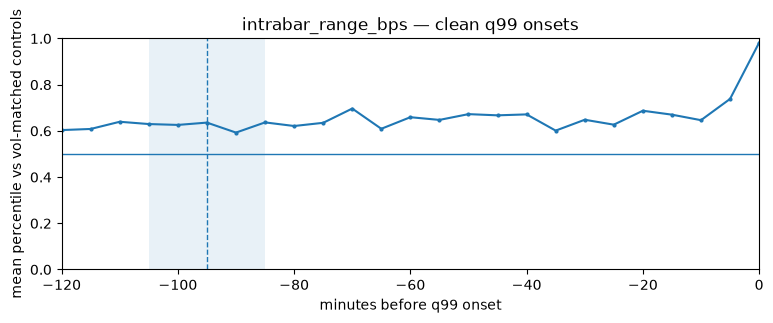

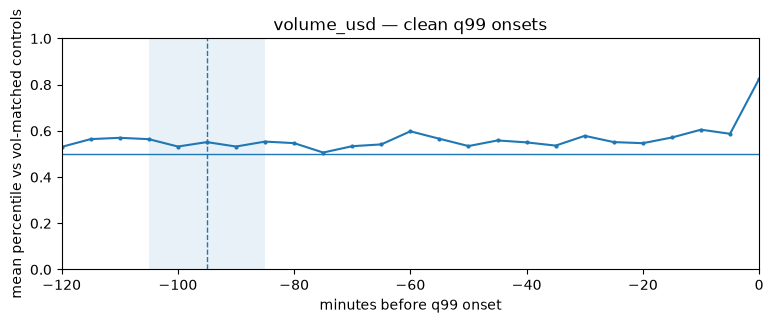

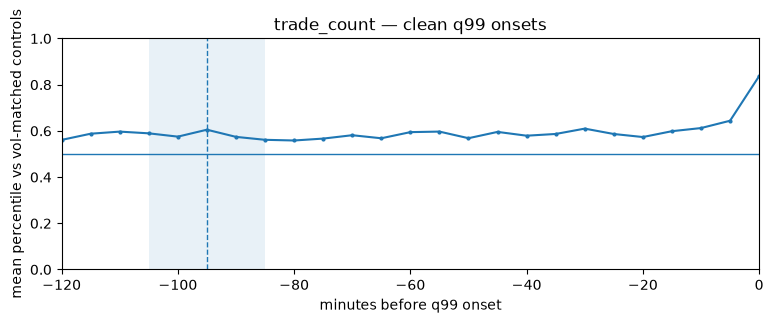

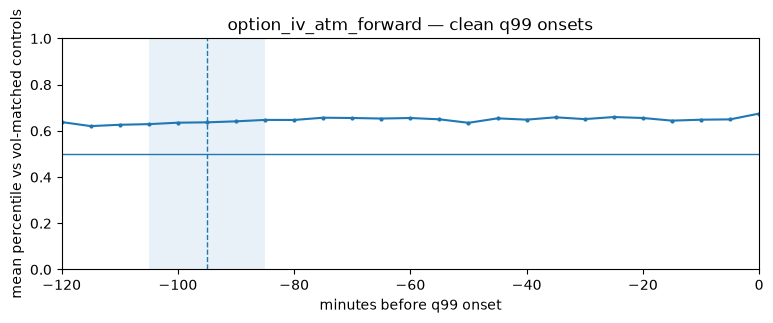

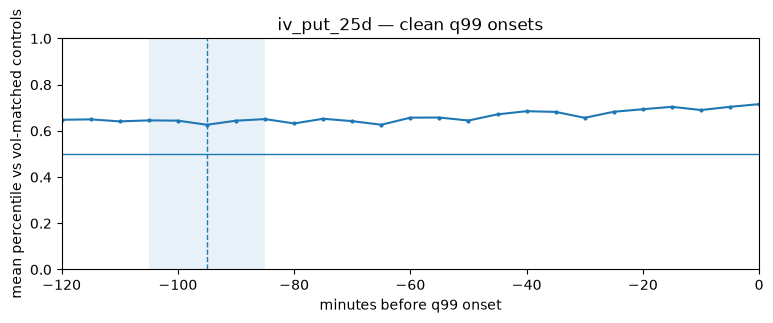

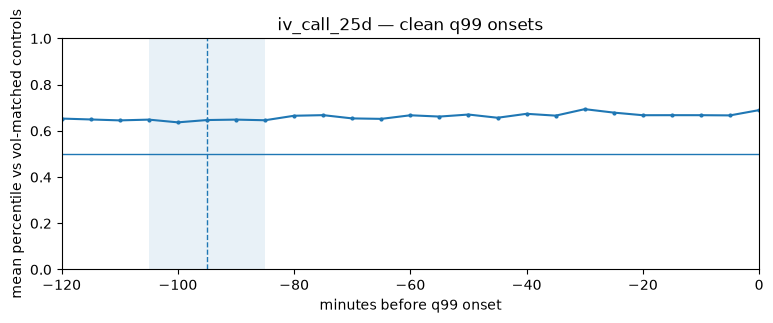

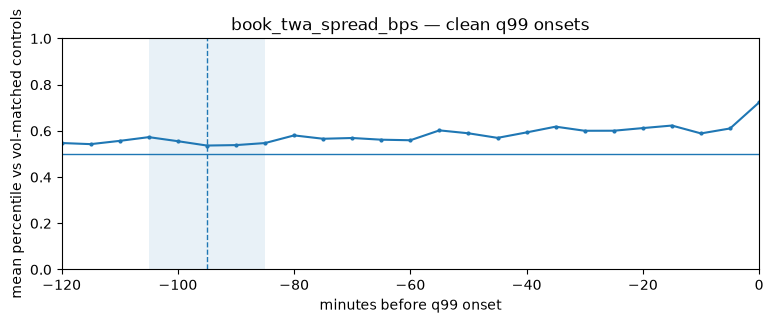

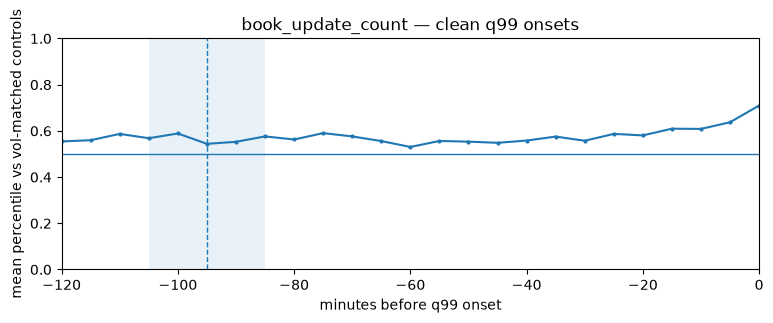

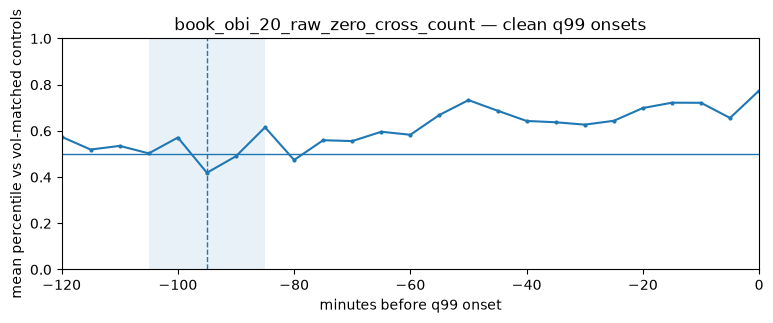

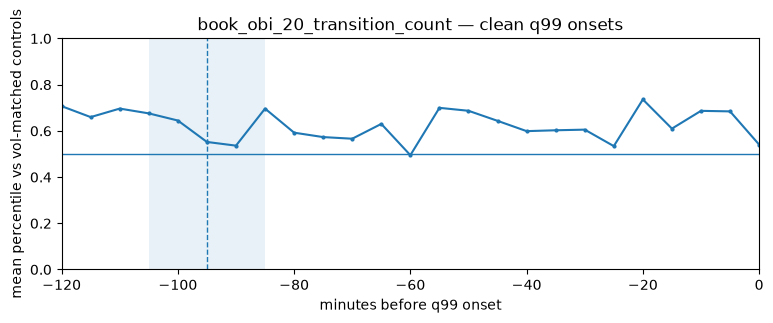

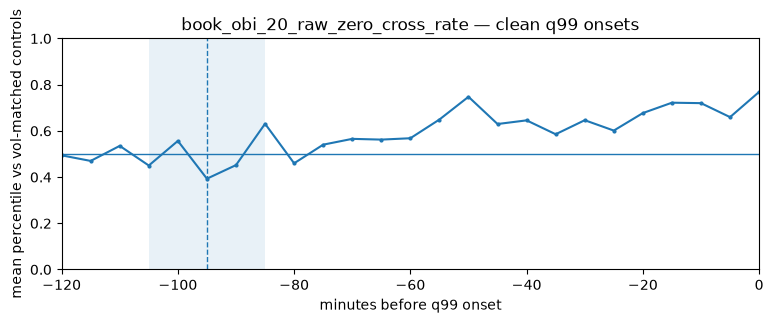

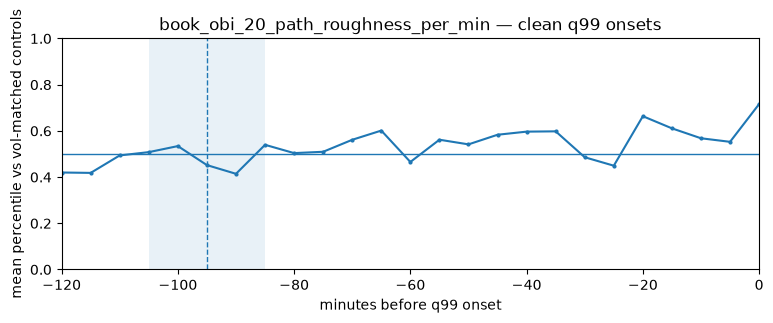

In [8]:
for feature in features:
    g = clean_profiles[clean_profiles.feature == feature].sort_values('rel_min')
    if not len(g):
        continue
    fig, ax = plt.subplots(figsize=(9,3))
    ax.plot(g.rel_min, g.mean_percentile, marker='o', markersize=2)
    ax.axhline(0.5, linewidth=1)
    ax.axvline(-95, linewidth=1, linestyle='--')
    ax.axvspan(-105, -85, alpha=0.10)
    ax.set_xlim(-120, 0)
    ax.set_ylim(0,1)
    ax.set_title(feature + ' — clean q99 onsets')
    ax.set_xlabel('minutes before q99 onset')
    ax.set_ylabel('mean percentile vs vol-matched controls')
    plt.show()


## 8. Family-level motif components

To avoid making a claim from one feature, construct event-level family summaries.

`activity_level`, `iv_level`, and `liquidity_book_activity_level` are average matched-control percentiles through the five-candle motif window.

`l2_rebound_95_to_post` asks whether L2 instability increases from the −95 candle into the −90/−85 candles.


In [9]:
components = qm.motif_component_scores(clean_scores, contract)
component_summary = qm.summarize_components(components)
bootstrap = qm.bootstrap_component_means(components)
loo = qm.leave_one_asset_out(components)
display(component_summary.round(4))
display(bootstrap.round(4))


,component,n_unique_event_times,mean,median,q25,q75,neutral_reference,mean_minus_neutral,share_above_neutral
0,activity_level,120,0.5719,0.5705,0.4250,0.7112,0.5,0.0719,0.6083
1,activity_center_95m,120,0.5851,0.5833,0.3750,0.7917,0.5,0.0851,0.5750
2,iv_level_level,119,0.6363,0.6827,0.4875,0.8278,0.5,0.1363,0.7227
3,iv_level_center_95m,119,0.6388,0.6786,0.4808,0.8542,0.5,0.1388,0.6975
4,liquidity_book_activity_level,108,0.5581,0.5634,0.4562,0.6750,0.5,0.0581,0.6389
5,liquidity_book_activity_center_95m,108,0.5403,0.5000,0.3839,0.7143,0.5,0.0403,0.4907
6,l2_instability_level,13,0.5317,0.4813,0.4125,0.6625,0.5,0.0317,0.4615
7,l2_instability_center_95m,13,0.4540,0.3750,0.2500,0.6000,0.5,-0.0460,0.4615
8,l2_rebound_95_to_post,13,0.0930,0.0750,-0.0312,0.2292,0.0,0.0930,0.6154
9,l2_notch_95,13,-0.0972,-0.0156,-0.2812,0.0156,0.0,-0.0972,0.3846


,component,n_unique_event_times,observed_mean,bootstrap_mean,bootstrap_q025,bootstrap_q975,bootstrap_seed,n_boot
0,activity_level,120,0.5719,0.5724,0.5368,0.6060,9505,4000
1,activity_center_95m,120,0.5851,0.5847,0.5386,0.6304,9505,4000
2,iv_level_level,119,0.6363,0.6361,0.5905,0.6802,9505,4000
3,iv_level_center_95m,119,0.6388,0.6387,0.5918,0.6831,9505,4000
4,liquidity_book_activity_level,108,0.5581,0.5583,0.5257,0.5902,9505,4000
5,liquidity_book_activity_center_95m,108,0.5403,0.5406,0.4996,0.5826,9505,4000
6,l2_instability_level,13,0.5317,0.5316,0.4268,0.6431,9505,4000
7,l2_instability_center_95m,13,0.4540,0.4536,0.3196,0.6016,9505,4000
8,l2_rebound_95_to_post,13,0.0930,0.0926,0.0161,0.1730,9505,4000
9,l2_notch_95,13,-0.0972,-0.0967,-0.1856,-0.0145,9505,4000


## 9. Leave-one-asset-out stability

A useful cross-asset motif should not disappear when one instrument is removed. Sparse L2 components should be interpreted especially cautiously because their event support is much smaller.


In [10]:
for component in sorted(loo.component.unique()) if len(loo) else []:
    g = loo[loo.component == component]
    print('\n', component)
    display(g[['excluded_asset','n_unique_event_times','mean','mean_minus_neutral']].round(4))



 activity_center_95m


,excluded_asset,n_unique_event_times,mean,mean_minus_neutral
1,AVAX,105,0.5643,0.0643
11,BTC,113,0.5758,0.0758
21,ETH,112,0.5891,0.0891
31,HYPE,102,0.5812,0.0812
41,SOL,112,0.5898,0.0898
51,TRX,89,0.5991,0.0991
61,XRP,112,0.5895,0.0895



 activity_level


,excluded_asset,n_unique_event_times,mean,mean_minus_neutral
0,AVAX,105,0.5655,0.0655
10,BTC,113,0.5616,0.0616
20,ETH,112,0.5696,0.0696
30,HYPE,102,0.5710,0.0710
40,SOL,112,0.5772,0.0772
50,TRX,89,0.5850,0.0850
60,XRP,112,0.5672,0.0672



 iv_level_center_95m


,excluded_asset,n_unique_event_times,mean,mean_minus_neutral
3,AVAX,104,0.6373,0.1373
13,BTC,112,0.6290,0.1290
23,ETH,112,0.6350,0.1350
33,HYPE,101,0.6473,0.1473
43,SOL,111,0.6438,0.1438
53,TRX,88,0.6445,0.1445
63,XRP,111,0.6270,0.1270


... (10 outputs left out)


 liquidity_book_activity_center_95m


,excluded_asset,n_unique_event_times,mean,mean_minus_neutral
5,AVAX,94,0.5386,0.0386
15,BTC,103,0.5276,0.0276
25,ETH,101,0.5399,0.0399
35,HYPE,91,0.5423,0.0423
45,SOL,101,0.5413,0.0413
55,TRX,80,0.5673,0.0673
65,XRP,101,0.5352,0.0352



 liquidity_book_activity_level


,excluded_asset,n_unique_event_times,mean,mean_minus_neutral
4,AVAX,94,0.5597,0.0597
14,BTC,103,0.5503,0.0503
24,ETH,101,0.5567,0.0567
34,HYPE,91,0.5632,0.0632
44,SOL,101,0.5647,0.0647
54,TRX,80,0.5674,0.0674
64,XRP,101,0.5535,0.0535


## 10. Asset-level view of the exact −95 candle


In [11]:
center_asset = (
    clean_scores[clean_scores.rel_bar == qm.MOTIF_CENTER_BAR]
    .groupby(['underlying','feature'])
    .agg(
        n_events=('event_id','nunique'),
        mean_center_95m_percentile=('percentile_vs_controls','mean'),
        median_center_95m_percentile=('percentile_vs_controls','median'),
        median_robust_diff_iqr=('robust_diff_iqr','median'),
    )
    .reset_index()
)
display(center_asset.sort_values(['feature','underlying']).round(4))


,underlying,feature,n_events,mean_center_95m_percentile,median_center_95m_percentile,median_robust_diff_iqr
0,AVAX,book_obi_20_path_roughness_per_min,2,0.7500,0.7500,0.9784
12,BTC,book_obi_20_path_roughness_per_min,2,0.5000,0.5000,-0.5825
24,ETH,book_obi_20_path_roughness_per_min,2,0.7750,0.7750,0.4371
36,HYPE,book_obi_20_path_roughness_per_min,3,0.3333,0.0000,-1.2198
48,SOL,book_obi_20_path_roughness_per_min,5,0.5000,0.5000,-0.0642
60,TRX,book_obi_20_path_roughness_per_min,3,0.5000,0.7500,0.0852
72,XRP,book_obi_20_path_roughness_per_min,1,1.0000,1.0000,10.7251
1,AVAX,book_obi_20_raw_zero_cross_count,2,1.0000,1.0000,1.9126
13,BTC,book_obi_20_raw_zero_cross_count,2,0.3750,0.3750,-0.4874
25,ETH,book_obi_20_raw_zero_cross_count,2,0.8000,0.8000,0.7609


## 11. Persist compact outputs


In [12]:
contract.to_csv(OUT / '05_motif_contract.csv', index=False)
event_meta.to_csv(OUT / '05_q99_thresholds_and_counts.csv', index=False)
summary.to_csv(OUT / '05_event_sample_summary.csv', index=False)
contamination.to_csv(OUT / '05_prior_q99_contamination.csv', index=False)
clean_events.to_csv(OUT / '05_clean_event_origins.csv', index=False)
clean_support.to_csv(OUT / '05_clean_match_support.csv', index=False)
clean_controls.to_csv(OUT / '05_clean_vol_matched_controls.csv', index=False)
all_profiles.to_csv(OUT / '05_all_event_profiles.csv', index=False)
clean_profiles.to_csv(OUT / '05_clean_event_profiles.csv', index=False)
local_all.to_csv(OUT / '05_all_local_motif_event_table.csv', index=False)
local_clean.to_csv(OUT / '05_clean_local_motif_event_table.csv', index=False)
motif_compare.to_csv(OUT / '05_motif_all_vs_clean.csv', index=False)
components.to_csv(OUT / '05_clean_motif_event_components.csv', index=False)
component_summary.to_csv(OUT / '05_component_summary.csv', index=False)
bootstrap.to_csv(OUT / '05_component_bootstrap.csv', index=False)
loo.to_csv(OUT / '05_leave_one_asset_out.csv', index=False)
center_asset.to_csv(OUT / '05_center95_by_asset.csv', index=False)

meta = {
    'version': qm.VERSION,
    'module': '05_minus95m_q99_motif',
    'motivation': 'visual pattern around -95m after extending q99 anatomy to +/-120m',
    'post_selection_exploratory': True,
    'q99_recomputed_inside_module': True,
    'motif_window_minutes': [-105,-100,-95,-90,-85],
    'motif_center_minutes': -95,
    'primary_sample': 'q99 onsets with no prior q99 bar in previous 120 minutes',
    'control_matching': 'same asset + exact 5m UTC clock + native-volatility history matching from Module 04',
    'simultaneous_asset_weighting': 'collapsed by exact event timestamp for pooled summaries',
    'bootstrap_note': 'descriptive stability only; motif selected after viewing same data',
    'no_predictive_model': True,
    'no_trading_claim': True,
    'start': START or 'earliest_available',
    'end': END or 'latest_available',
    'n_rows': int(len(df)),
    'n_all_asset_events': int(len(events)),
    'n_clean_asset_events': int(len(clean_events)),
    'n_all_unique_event_times': int(events.event_time.nunique()),
    'n_clean_unique_event_times': int(clean_events.event_time.nunique()),
}
(OUT / '05_run_metadata.json').write_text(json.dumps(meta, indent=2))
print('wrote Module 05 outputs to', OUT)


wrote Module 05 outputs to D:\Projects\deribit_market_data\notebooks\Volatility_Dynamics\05


## Interpretation boundary

Module 05 can tell us whether the visually discovered −95m motif is stable, cross-asset, and still present after removing events preceded by another q99 shock.

It **cannot** establish that the motif predicts q99 prospectively, because the −95m window was discovered on this same historical sample. If the clean motif survives, the next legitimate step is to freeze its exact definition and test it chronologically on future/non-discovery observations.
